# Assignment 4

In [3]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy as sp

## Question 1
### Part a)
The null hypothesis is that the medication has no effect. This can be described by a binomial distribution with $p=0.5$ and $N=100$:
$${100 \choose k} (0.5)^k (0.5)^{100-k} = {100 \choose k} 0.5^{100}$$
The null hypothesis could thus be rejected at the 95% CL for the minimum $r$ such that 
$$\sum_{k=1}^r {100 \choose k} 0.5^{100}  \geq 0.95 $$

In [29]:
n = 100
p = 0.5
CL = 0.95

for k in range(n+1):
    total = sp.stats.binom.cdf(k,n,p)
    if total >= CL:
        break 

print(f'This means that {k} out of {n} patients need to survive to reject the null hypothesis at the {CL*100}% CL.')

This means that 58 out of 100 patients need to survive to reject the null hypothesis at the 95.0% CL.


In [30]:
# this one just for fun
n = 100
p = 0.5
CL = 1 - 1e-6 # approximately 5sigma CL

for k in range(n+1):
    total = sp.stats.binom.cdf(k,n,p)
    if total >= CL:
        break 

print(f'{k} out of {n} patients need to survive to reject the null hypothesis at the {CL*100}% CL (particle physics standards).')

73 out of 100 patients need to survive to reject the null hypothesis at the 99.9999% CL (particle physics standards).


### Part b)


## Question 2


Text(0.5, 1.0, 'Odds of winning at least one game after $n$ plays')

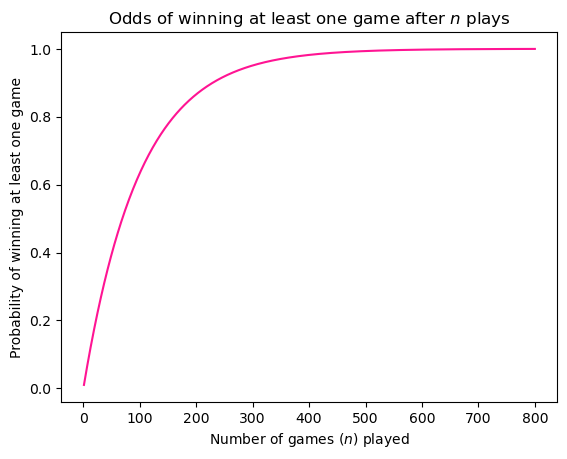

In [46]:
p = 0.01
num_trials = 800
n = np.linspace(1,num_trials,num_trials)
trials = 1-sp.stats.binom.pmf(0,n,p)      # take the complement of winning 0 times 

fig, ax = plt.subplots(1,1)
ax.plot(n,trials,color='deeppink')

ax.set_xlabel('Number of games ($n$) played')
ax.set_ylabel('Probability of winning at least one game')

ax.set_title('Odds of winning at least one game after $n$ plays')


In [51]:
print(f'The number of games that must be played before the odds of winning at least once exceed 50% is {np.min(n[trials >= 0.5]):.0f}.')

The number of games that must be played before the odds of winning at least once exceed 50% is 69.


## Question 3 
### Part a)

In [54]:
def modela(x):
    '''
    '''
    return 3*x**2 - 1

In [60]:
def chi2_val(model,y,x,sigma):
    '''
    '''
    return np.sum((y - model(x))**2 / sigma**2)

In [ ]:
sigma = 0.02
x = np.array([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0])
y = np.array([-0.951,-0.842,-0.741,-0.492,-0.229,0.118,0.494,0.957,1.449,2.055])

N = len(x)


val = chi2_val(modela,y,x,sigma)
df = N-1

p_val = sp.stats.chi2.cdf(val, df)

print(f'The p-value that y does not depend on x according to y=3x^2-1 is {p_val:.4f}.')


The p-value that y does not depend on x according to y=3x^2-1 is 0.9968.


### Part b)
This systematic will only affect the result through sigma being larger. Including the systematic the model becomes 
$$y = 3x^2 - 1 + ax$$
and so rather than just including the statistical uncertainty of $x$ ($\sigma_x = 0.02$), we include the systematic uncertainty of $a$ ($\sigma_a=0.05$) through the formula. Since these errors are uncorrelated, we can find the total uncertainty by:

$$\sigma^2 = \sigma_x^2 + \left(\frac{dy}{da}\right)^2 \sigma_a^2 = \sigma_x^2 + x^2 \sigma_a^2 $$

In [ ]:
sigma = np.sqrt(0.02**2 + x**2*0.05**2)

val = chi2_val(modela,y,x,sigma)
df = N-1

p_val = sp.stats.chi2.cdf(val, df)

print(f'The p-value that y does not depend on x according to y=3x^2-1 is {p_val:.4f}.')


The p-value that y does not depend on x according to y=3x^2-1 is 0.5330.


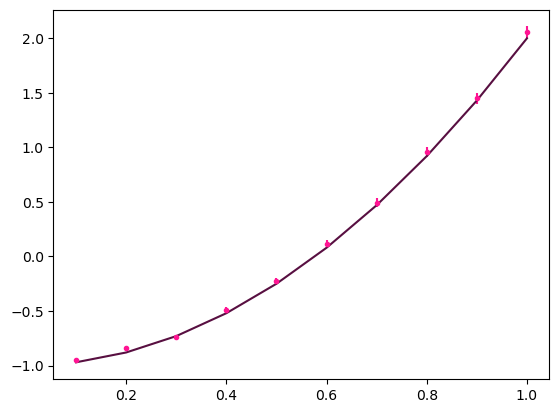

In [ ]:
# DELETE THIS !!

zoom = False

sigma = np.sqrt(0.02**2 + x**2*0.05**2)

fig, ax = plt.subplots(1,1)
ax.errorbar(x,y,yerr=sigma,color='deeppink',fmt='.')
ax.plot(x,modela(x),color='xkcd:plum')

if zoom:
    ax.set_xlim(0.099,0.21)
    ax.set_ylim(-1,-0.75)

## Question 4 

In [447]:
def modelq4(L,c,T,T0):
    '''
    '''
    return L + c*(T-T0)

In [448]:
def chi2_val_q4(model,y,T,L,c,T0,sigma_T,sigma_L):
    '''
    '''
    # loop for the two rulers

    ruler_chi2 = []
    for i in range(2):
        sigma2 = sigma_L[i]**2 + (c[i]**2 + c[0]*c[1]) * sigma_T**2 
        ruler_chi2.append((y - model(L[i],c[i],T,T0))**2/ sigma2)

    ruler_chi2 = np.array(ruler_chi2)
    return np.sum(ruler_chi2,axis=0)

In [ ]:
def q4_likelihood(y,T,L,c,T_meas,T0,sigma_T,sigma_L):
    '''
    '''
    chi2_val = chi2_val_q4(modelq4,y,T,L,c,T0,sigma_T,sigma_L)

    return chi2_val  - 2 * np.log(sp.stats.norm.pdf(T,loc=T_meas,scale=np.sqrt(sigma_T))) 


/var/folders/gz/v3gvmwcx05gc_d2jg_h0x28c0000gn/T/ipykernel_9663/3264781534.py:30: UserWarning: The following kwargs were not used by contour: 'aspect'
  contour_set = ax.contour(likelihood,


<a list of 7 text.Text objects>

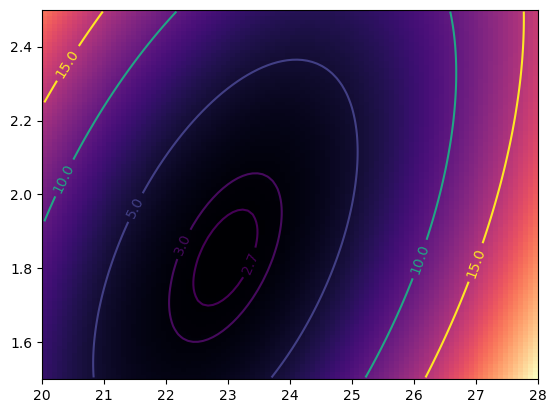

In [ ]:
ci = (0.1,0.2)
Li = (2,2.3)
sigma_Li = (0.1,0.1)
T0 = 25
T_meas = 23
sigma_T = 2

num_vals = 100
yrange = (1.5,2.5)
Trange = (20,28)

y = np.linspace(yrange[0],yrange[1],num_vals)
T = np.linspace(Trange[0],Trange[1],num_vals)

Tplt, yplt = np.meshgrid(T,y)

likelihood = q4_likelihood(yplt,Tplt,Li,ci,T_meas,T0,sigma_T,sigma_Li)




fig,ax=plt.subplots(1,1)

ax.imshow(likelihood,
           origin="lower",
           extent=(Trange[0],Trange[1],yrange[0],yrange[1]),
           aspect='auto',
           cmap='magma') 

contour_set = ax.contour(likelihood,
           origin="lower",
           extent=(Trange[0],Trange[1],yrange[0],yrange[1]),
           aspect='auto',
           levels=[2.7,3,5,10,15]) # not correct contours

ax.clabel(contour_set)

## Question 5
### Part a)

The relevant equations needed to relate the data which is given in terms of $(z,m)$ and $\Omega_\Lambda$ are: 
- $m = -2.5 \log L$
- $L = \frac{L_0}{D}$
- $D = \frac{1}{H_0}\left[z + \frac{z^2}{2}(1-q_0)\right]$
- $q_0 = \frac{\Omega_m}{2} - \Omega_\Lambda$
- $\Omega_m + \Omega_\Lambda = 1$ (assumption that the universe is flat)

The last two equations can be combined to have $\Omega_\Lambda$ in terms of $q_0$
$$q_0 = \frac{1- \Omega_\Lambda}{2} - \Omega_\Lambda = \frac{1}{2} - \frac{3}{2}\Omega_\Lambda$$
and putting this into the third equation gives
$$D = \frac{1}{H_0}\left[z + \frac{z^2}{2}\left(\frac{1}{2} + \frac{3}{2}\Omega_\Lambda\right)\right]$$
then we can write this in terms of $m$ as 
$$m = -2.5 \log \frac{L_0}{H_0} + 2.5 \log \left[z + \frac{z^2}{2}\left(\frac{1}{2} + \frac{3}{2}\Omega_\Lambda\right)\right]$$

In [429]:
def model_q5(z,omegaL,L0H0): #
    '''
    Define the model as above. 
    '''
    return -2.5 * np.log10(L0H0) + 2.5 * np.log10(z + z**2/2 * (0.5 + 1.5 * omegaL))

In [430]:
def chi2_val_q5(model,m,z,omegaL,sigma_m,L0H0):
    '''
    '''

    # loop over values of omegaL

    omega_chi2 = []
    for i in range(len(omegaL)):
        sigma2 = sigma_m**2  

        omega_chi2.append(np.sum((m - model(z,omegaL[i],L0H0))**2 / sigma2))

    omega_chi2 = np.array(omega_chi2)
    return omega_chi2

In [445]:
def likelihood_q5(model,m,z,omegaL,sigma_m,L0H0):
    '''
    '''
    chi_vals = chi2_val_q5(model,m,z,omegaL,sigma_m,L0H0)
    # print(chi_vals)
    # return sp.stats.chi2.pdf(chi_vals, len(z)-1)
    return chi_vals
    

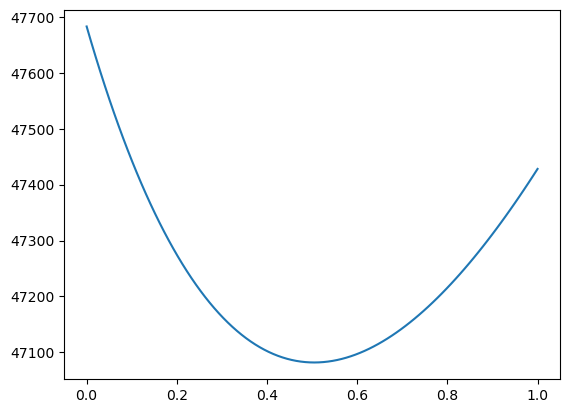

In [ ]:

# load in the data 
z_data,m_data = np.loadtxt('/Users/josephinebrewster/Documents/University/Physics 509C/phys509c/supernovae.txt').T
sigma_m = 0.1

omegaL = np.linspace(0,1,100)
L0H0 = 0.4e-15 # didn't find the correct value to put here oops 

llh = likelihood_q5(model_q5,m_data,z_data,omegaL,sigma_m,L0H0)

fig,ax = plt.subplots(1,1)
ax.plot(omegaL,llh)



### Part b)